# Classificação de demissões • Layoff Survival
### Redes neurais MLP, comparação de atributos e avaliação fora da amostra

**Objetivo:** estimar `laid_off` (`1` = demitido; `0` = mantido) no dataset sintético de Sergey Nefedov, dando continuidade ao [EDA do projeto](https://giuvallente.github.io/neuralNetworks-Documentation/project/eda/).

**Este notebook já contém os resultados da execução.** Para reproduzi-los, execute as células em ordem. O CSV original está incorporado em formato comprimido: não é necessário enviar arquivos, usar credenciais do Kaggle ou importar módulos do repositório. A instalação de dependências, se necessária, exige internet. O treinamento usa CPU.

| Elemento | Definição |
|---|---|
| Fonte | [Layoff Survival — Who Actually Gets Cut?](https://www.kaggle.com/datasets/sergionefedov/layoff-survival-who-actually-gets-cut), versão 1, licença CC0 |
| Amostra | 30.000 registros sintéticos; 6.107 positivos |
| Separação | 80% desenvolvimento / 20% teste, estratificados, semente 42 |
| Seleção | Validação cruzada estratificada com 5 folds no desenvolvimento |
| Métrica principal | Average Precision (AP), resumo da curva precisão–recall |
| Modelo principal | Perceptron multicamadas (MLP) |
| Referências | Dummy, regressão logística e Random Forest |

Os resultados descrevem o processo sintético que gerou esta base. Não demonstram causas de demissão nem validam decisões sobre funcionários reais.

## 1. Protocolo experimental

Mantemos as decisões do EDA: retirar `employee_id`, separar o alvo, preservar outliers plausíveis, padronizar as três variáveis numéricas e codificar as categorias com one-hot. PCA, t-SNE e UMAP não entram no classificador.

Comparamos **baseline** (10 atributos) e **extended** (os mesmos 10 + `team_wind_down`, `cost_center_type`, `role_redundant`). O baseline do projeto é mais amplo que o baseline de três atributos sugerido pelo autor; este último aparece em uma análise adicional.

1. Reservar o teste com exatamente a divisão do EDA.
2. Avaliar modelos e configurações nos mesmos cinco folds.
3. Para cada MLP, usar uma divisão interna do treino do fold para escolher o número de épocas; então reiniciar e treinar nos quatro folds completos por esse número de épocas.
4. Escolher a configuração da MLP pelo AP médio de validação do conjunto extended. Aplicar essa mesma configuração aos dois conjuntos para uma comparação controlada.
5. Escolher os limiares por F1 nas previsões *out-of-fold* (OOF) do desenvolvimento.
6. Congelar todas as escolhas, ajustar no desenvolvimento completo e avaliar o teste uma única vez como etapa final. As análises posteriores não alteram os modelos.

As médias de CV são usadas para seleção; não são estimativas sem viés do melhor resultado após a busca. O teste reservado é a avaliação final. Como o EDA já inspecionou o dataset completo, esse teste não equivale a uma amostra externa coletada depois do projeto.

In [1]:
# Instala somente se alguma dependência essencial estiver ausente/incompatível.
import importlib.util
import importlib.metadata
import subprocess
import sys

required = {
    'numpy': 'numpy>=1.26', 'pandas': 'pandas>=2.2',
    'sklearn': 'scikit-learn>=1.7,<1.9', 'matplotlib': 'matplotlib>=3.8',
    'scipy': 'scipy>=1.12', 'joblib': 'joblib>=1.3',
    'threadpoolctl': 'threadpoolctl>=3.2', 'packaging': 'packaging>=23',
}
missing = [spec for module, spec in required.items()
           if importlib.util.find_spec(module) is None]
if importlib.util.find_spec('sklearn'):
    major_minor = tuple(map(int, importlib.metadata.version('scikit-learn').split('.')[:2]))
    if major_minor < (1, 7):
        missing.append('scikit-learn>=1.7,<1.9')
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])

import hashlib, platform, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn import __version__ as sklearn_version
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (
    average_precision_score, roc_auc_score, accuracy_score,
    balanced_accuracy_score, precision_score, recall_score, f1_score,
    log_loss, brier_score_loss, classification_report, confusion_matrix,
    precision_recall_curve, roc_curve, ConfusionMatrixDisplay,
)
from sklearn.inspection import permutation_importance
from threadpoolctl import threadpool_limits

%matplotlib inline
SEED = 42
N_SPLITS = 5
MAX_EPOCHS = 100
PATIENCE = 12
MIN_DELTA = 0.0005
BATCH_SIZE = 256
BOOTSTRAPS = 1000
np.random.seed(SEED)
# Evita excesso de threads para matrizes pequenas e facilita reprodução em CPU.
thread_limiter = threadpool_limits(limits=1)
plt.rcParams.update({
    'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titlesize': 12, 'axes.labelsize': 10, 'font.size': 10,
    'axes.prop_cycle': plt.cycler(color=['#2456A6', '#DB6A36', '#2B8C82', '#8C59A2']),
})
VERSIONS = {'python': platform.python_version()}
for package in ['numpy', 'pandas', 'scikit-learn', 'scipy', 'matplotlib', 'joblib']:
    VERSIONS[package] = importlib.metadata.version(package)
display(pd.Series(VERSIONS, name='Versão executada').to_frame())

,Versão executada
python,3.13.14
numpy,2.5.4
pandas,3.1.1
scikit-learn,1.9.1
scipy,1.18.1
matplotlib,3.11.2
joblib,1.6.0


## 2. Dados locais e confer?ncia

O CSV j? baixado deve estar em `data/layoff-survival/layoff_survival.csv`. A c?lula seguinte l? esse arquivo e confere o hash SHA-256 esperado para a vers?o 1 do dataset.

N?o repetimos o EDA: verificamos apenas esquema, alvo e consist?ncia dos registros usados no treinamento. Perfis repetidos com identificadores diferentes s?o preservados como no EDA; n?o representam necessariamente a mesma pessoa sint?tica.

In [2]:
DATA_PATH = Path('data') / 'layoff-survival' / 'layoff_survival.csv'
if not DATA_PATH.is_file():
    raise FileNotFoundError(f'CSV n?o encontrado: {DATA_PATH.resolve()}')
DATASET_SHA256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
assert DATASET_SHA256 == '929fad1d4188017c96353a850039b4a60bc5ca7ee68c2daee5300d6d6d933b4e', \
    'O hash do CSV n?o corresponde ? vers?o 1 esperada.'
df = pd.read_csv(DATA_PATH)
print(f'CSV carregado de {DATA_PATH}: {df.shape[0]:,} linhas ? {df.shape[1]} colunas.')
print('SHA-256:', DATASET_SHA256)


CSV carregado de data\layoff-survival\layoff_survival.csv: 30,000 linhas ? 15 colunas.
SHA-256: 929fad1d4188017c96353a850039b4a60bc5ca7ee68c2daee5300d6d6d933b4e


In [3]:
NUMERIC = ['tenure_years', 'performance_rating', 'salary_k_usd']
CATEGORICAL = ['department', 'cost_center_type', 'mgmt_layer', 'level']
BINARY = ['team_wind_down', 'is_recent_hire', 'on_pip',
          'high_salary', 'remote', 'role_redundant']
STRUCTURAL = ['team_wind_down', 'cost_center_type', 'role_redundant']
ALL_FEATURES = NUMERIC + CATEGORICAL + BINARY
FEATURE_SETS = {
    'baseline': [c for c in ALL_FEATURES if c not in STRUCTURAL],
    'extended': [c for c in ALL_FEATURES if c not in STRUCTURAL] + STRUCTURAL,
}
TARGET = 'laid_off'
assert df.shape == (30000, 15)
assert set(df.columns) == set(ALL_FEATURES + ['employee_id', TARGET])
assert df[TARGET].notna().all() and set(df[TARGET].unique()) == {0, 1}
assert df['employee_id'].notna().all() and df['employee_id'].is_unique
assert df[BINARY].isin([0, 1]).all().all()
assert df['tenure_years'].ge(0).all()
assert df['performance_rating'].between(1, 5).all()
assert df['salary_k_usd'].gt(0).all()
assert df['is_recent_hire'].eq(df['tenure_years'].lt(1).astype(int)).all()

quality = pd.Series({
    'Registros': len(df), 'Valores ausentes': int(df.isna().sum().sum()),
    'Duplicatas exatas': int(df.duplicated().sum()),
    'Duplicatas sem identificador': int(df.drop(columns='employee_id').duplicated().sum()),
    'Classe 0 — mantido': int(df[TARGET].eq(0).sum()),
    'Classe 1 — demitido': int(df[TARGET].eq(1).sum()),
}, name='Conferência')
display(quality.to_frame())
display(pd.DataFrame([
    {'Conjunto': name, 'Nº atributos': len(cols), 'Atributos': ', '.join(cols)}
    for name, cols in FEATURE_SETS.items()
]))

,Conferência
Registros,30000
Valores ausentes,0
Duplicatas exatas,0
Duplicatas sem identificador,8
Classe 0 — mantido,23893
Classe 1 — demitido,6107


,Conjunto,Nº atributos,Atributos
0,baseline,10,"tenure_years, performance_rating, salary_k_usd..."
1,extended,13,"tenure_years, performance_rating, salary_k_usd..."


## 3. Divisão de dados e pré-processamento

A estratificação preserva a proporção de positivos. Imputação, padronização e categorias do one-hot são aprendidas somente no treino correspondente, inclusive na divisão interna usada para early stopping. As variáveis binárias permanecem em 0/1. `handle_unknown='ignore'` mantém a dimensão quando aparece uma categoria nova.

O StandardScaler iguala escalas; **não remove nem torna o modelo robusto a outliers**. Não fazemos SMOTE ou balanceamento do teste. O desequilíbrio é tratado por métricas, pesos em uma parte das configurações e ajuste do limiar no desenvolvimento.

In [4]:
X = df.drop(columns=['employee_id', TARGET])
y = df[TARGET].astype(int)
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED,
)
assert set(X_dev.index).isdisjoint(X_test.index)
assert len(X_dev) + len(X_test) == len(df)
assert 'employee_id' not in X_dev and TARGET not in X_dev
cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
FOLDS = list(cv.split(X_dev, y_dev))
display(pd.DataFrame([
    {'Partição': name, 'Registros': len(labels),
     'Positivos': int(labels.sum()), 'Positivos (%)': 100 * labels.mean()}
    for name, labels in [('Desenvolvimento', y_dev), ('Teste reservado', y_test)]
]).round(3))

def make_preprocessor(columns):
    columns = list(columns)
    assert not ({'employee_id', TARGET} & set(columns))
    assert set(columns).issubset(ALL_FEATURES)
    branches = []
    numeric = [c for c in NUMERIC if c in columns]
    categorical = [c for c in CATEGORICAL if c in columns]
    binary = [c for c in BINARY if c in columns]
    if numeric:
        branches.append(('numeric', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler()),
        ]), numeric))
    if categorical:
        branches.append(('categorical', Pipeline([
            ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
            ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
        ]), categorical))
    if binary:
        branches.append(('binary', SimpleImputer(strategy='most_frequent'), binary))
    return ColumnTransformer(branches, remainder='drop')

# Conferência sobre o treino do primeiro fold; não ajusta nada no teste.
for name, columns in FEATURE_SETS.items():
    prep = make_preprocessor(columns)
    a = prep.fit_transform(X_dev.iloc[FOLDS[0][0]])
    b = prep.transform(X_dev.iloc[FOLDS[0][1]])
    assert np.isfinite(a).all() and np.isfinite(b).all()
    print(f'{name}: treino={a.shape}; validação={b.shape}')

# Perfis sintéticos coincidentes são uma limitação do split aleatório.
dev_profiles = pd.util.hash_pandas_object(X_dev, index=False)
test_profiles = pd.util.hash_pandas_object(X_test, index=False)
print('Perfis de teste idênticos a algum perfil de desenvolvimento:',
      int(test_profiles.isin(set(dev_profiles)).sum()))

,Partição,Registros,Positivos,Positivos (%)
0,Desenvolvimento,24000,4886,20.358
1,Teste reservado,6000,1221,20.350


baseline: treino=(19200, 24); validação=(4800, 24)
extended: treino=(19200, 29); validação=(4800, 29)
Perfis de teste idênticos a algum perfil de desenvolvimento: 4


## 4. Modelos e critérios de escolha

Cada MLP tem camadas densas, ativação ReLU ou tanh, saída sigmoide, entropia cruzada binária, otimizador Adam, taxa inicial de aprendizado 0,001 e lotes de 256. A penalização L2 é controlada por `alpha`. O early stopping monitora **AP em uma validação interna de 15%**, com paciência de 12 épocas e teto de 100.

| Configuração | Camadas ocultas | Ativação | L2 (alpha) | Pesos de classe |
|---|---|---|---|---|
| MLP_16 | 16 | ReLU | 0,001 | Não |
| MLP_32_16 | 32 → 16 | ReLU | 0,01 | Não |
| MLP_32_16_bal | 32 → 16 | ReLU | 0,01 | Inversos das frequências do treino |
| MLP_tanh_bal | 32 → 16 | tanh | 0,01 | Inversos das frequências do treino |

Os pesos são calculados novamente em cada treino: $w_c = n/(2n_c)$. Não se usa a frequência do teste. Previsões de redes ponderadas não devem ser interpretadas automaticamente como probabilidades calibradas.

**Métricas:** AP é a principal, pois a classe positiva representa aproximadamente 20% da base. AP é calculada por `average_precision_score`, não pela integral trapezoidal da curva PR. ROC-AUC mede ordenação; F1, precisão e recall dependem do limiar. Acurácia e balanced accuracy complementam a avaliação. Dummy serve como referência mínima; a regressão logística é especialmente relevante porque o gerador do dataset utiliza uma função logística.

In [5]:
MLP_CONFIGS = {
    'MLP_16': dict(hidden_layer_sizes=(16,), activation='relu', alpha=0.001, balanced=False),
    'MLP_32_16': dict(hidden_layer_sizes=(32, 16), activation='relu', alpha=0.01, balanced=False),
    'MLP_32_16_bal': dict(hidden_layer_sizes=(32, 16), activation='relu', alpha=0.01, balanced=True),
    'MLP_tanh_bal': dict(hidden_layer_sizes=(32, 16), activation='tanh', alpha=0.01, balanced=True),
}
REFERENCES = {
    'Dummy': DummyClassifier(strategy='prior'),
    'Logistica': LogisticRegression(C=1.0, max_iter=1000, random_state=SEED),
    'RandomForest': RandomForestClassifier(
        n_estimators=150, max_depth=10, min_samples_leaf=15,
        max_features='sqrt', class_weight='balanced', n_jobs=1, random_state=SEED,
    ),
}

def make_mlp(config, seed):
    params = {k: v for k, v in config.items() if k != 'balanced'}
    return MLPClassifier(
        **params, solver='adam', learning_rate_init=0.001,
        batch_size=BATCH_SIZE, max_iter=1, shuffle=True,
        early_stopping=False, random_state=seed,
    )

def sample_weights(labels, config):
    if config.get('balanced', False):
        return compute_sample_weight(class_weight='balanced', y=labels)
    return None

def fit_fixed_epochs(X_train, y_train, columns, config, epochs, seed):
    prep = make_preprocessor(columns)
    a = np.asarray(prep.fit_transform(X_train), dtype=np.float32)
    labels = np.asarray(y_train, dtype=int)
    weights = sample_weights(labels, config)
    model = make_mlp(config, seed)
    for _ in range(int(epochs)):
        model.partial_fit(a, labels, classes=np.array([0, 1]), sample_weight=weights)
    return Pipeline([('preprocessing', prep), ('model', model)])

def choose_epochs(X_train, y_train, columns, config, seed):
    positions = np.arange(len(y_train))
    inner_train, inner_val = train_test_split(
        positions, test_size=0.15, stratify=y_train, random_state=seed,
    )
    prep = make_preprocessor(columns)
    a = np.asarray(prep.fit_transform(X_train.iloc[inner_train]), dtype=np.float32)
    b = np.asarray(prep.transform(X_train.iloc[inner_val]), dtype=np.float32)
    ya = np.asarray(y_train.iloc[inner_train], dtype=int)
    yb = np.asarray(y_train.iloc[inner_val], dtype=int)
    model = make_mlp(config, seed)
    weights = sample_weights(ya, config)
    history, best_ap, best_epoch, wait = [], -np.inf, 1, 0
    for epoch in range(1, MAX_EPOCHS + 1):
        model.partial_fit(a, ya, classes=np.array([0, 1]), sample_weight=weights)
        pa, pb = model.predict_proba(a)[:, 1], model.predict_proba(b)[:, 1]
        ap = average_precision_score(yb, pb)
        history.append({
            'epoch': epoch, 'train_loss': log_loss(ya, pa, labels=[0, 1]),
            'val_loss': log_loss(yb, pb, labels=[0, 1]),
            'train_ap': average_precision_score(ya, pa), 'val_ap': ap,
        })
        if ap > best_ap + MIN_DELTA:
            best_ap, best_epoch, wait = ap, epoch, 0
        else:
            wait += 1
        if wait >= PATIENCE:
            break
    return best_epoch, pd.DataFrame(history)

def classification_metrics(labels, probabilities, threshold=0.5):
    pred = (np.asarray(probabilities) >= threshold).astype(int)
    return {
        'AP': average_precision_score(labels, probabilities),
        'ROC_AUC': roc_auc_score(labels, probabilities),
        'Accuracy': accuracy_score(labels, pred),
        'Balanced_accuracy': balanced_accuracy_score(labels, pred),
        'Precision': precision_score(labels, pred, zero_division=0),
        'Recall': recall_score(labels, pred, zero_division=0),
        'F1': f1_score(labels, pred, zero_division=0),
        'Log_loss': log_loss(labels, probabilities, labels=[0, 1]),
        'Brier': brier_score_loss(labels, probabilities),
    }

## 5. Treinamento e validação cruzada

Cada previsão OOF é produzida por um modelo que não usou aquela linha para ajustar parâmetros, pré-processar dados ou escolher épocas. Os mesmos folds e sementes são utilizados na comparação baseline × extended. A busca é pequena e explícita; não é uma otimização exaustiva.

O treino interno da MLP é descartado após a escolha das épocas. O modelo do fold é reiniciado e ajustado em todos os 19.200 registros de treino antes de prever os 4.800 registros externos de validação.

In [6]:
fold_results = []
oof_predictions = {}
learning_histories = {}
epoch_choices = {}
start_all = time.perf_counter()

def run_cv(feature_name, columns, model_names):
    for model_name in model_names:
        key = (feature_name, model_name)
        oof = np.full(len(y_dev), np.nan)
        epochs = []
        start = time.perf_counter()
        for fold, (train_idx, val_idx) in enumerate(FOLDS, 1):
            train_x, valid_x = X_dev.iloc[train_idx], X_dev.iloc[val_idx]
            train_y, valid_y = y_dev.iloc[train_idx], y_dev.iloc[val_idx]
            seed = SEED + fold
            if model_name in MLP_CONFIGS:
                config = MLP_CONFIGS[model_name]
                n_epochs, history = choose_epochs(train_x, train_y, columns, config, seed)
                estimator = fit_fixed_epochs(train_x, train_y, columns, config, n_epochs, seed)
                learning_histories[(feature_name, model_name, fold)] = history
                epochs.append(n_epochs)
            else:
                estimator = Pipeline([
                    ('preprocessing', make_preprocessor(columns)),
                    ('model', clone(REFERENCES[model_name])),
                ]).fit(train_x, train_y)
                n_epochs = np.nan
            prob = estimator.predict_proba(valid_x)[:, 1]
            oof[val_idx] = prob
            fold_results.append({
                'feature_set': feature_name, 'model': model_name, 'fold': fold,
                'epochs': n_epochs, **classification_metrics(valid_y, prob),
            })
        assert np.isfinite(oof).all() and ((oof >= 0) & (oof <= 1)).all()
        oof_predictions[key] = oof
        epoch_choices[key] = epochs
        print(f'{feature_name:18s} | {model_name:18s} | '
              f'AP OOF={average_precision_score(y_dev, oof):.4f} | '
              f'{time.perf_counter()-start:.1f}s', flush=True)

for feature_name, columns in FEATURE_SETS.items():
    run_cv(feature_name, columns, list(REFERENCES) + list(MLP_CONFIGS))

cv_results = pd.DataFrame(fold_results)
cv_summary = cv_results.groupby(['feature_set', 'model']).agg(
    AP_mean=('AP', 'mean'), AP_std=('AP', 'std'),
    ROC_mean=('ROC_AUC', 'mean'), ROC_std=('ROC_AUC', 'std'),
    F1_05_mean=('F1', 'mean'), Recall_05_mean=('Recall', 'mean'),
    epochs_median=('epochs', 'median'),
).reset_index().sort_values(['feature_set', 'AP_mean'], ascending=[True, False])
print(f'\nTempo da comparação principal: {(time.perf_counter()-start_all)/60:.1f} min')
display(cv_summary.round(4))

baseline           | Dummy              | AP OOF=0.2036 | 0.4s
baseline           | Logistica          | AP OOF=0.3738 | 0.6s
baseline           | RandomForest       | AP OOF=0.3671 | 9.4s
baseline           | MLP_16             | AP OOF=0.3704 | 13.9s
baseline           | MLP_32_16          | AP OOF=0.3656 | 16.6s
baseline           | MLP_32_16_bal      | AP OOF=0.3662 | 10.7s
baseline           | MLP_tanh_bal       | AP OOF=0.3703 | 8.7s
extended           | Dummy              | AP OOF=0.2036 | 0.3s
extended           | Logistica          | AP OOF=0.6667 | 0.4s
extended           | RandomForest       | AP OOF=0.6501 | 12.3s
extended           | MLP_16             | AP OOF=0.6637 | 10.8s
extended           | MLP_32_16          | AP OOF=0.6608 | 11.8s
extended           | MLP_32_16_bal      | AP OOF=0.6604 | 13.1s
extended           | MLP_tanh_bal       | AP OOF=0.6611 | 14.9s

Tempo da comparação principal: 2.1 min


,feature_set,model,AP_mean,AP_std,ROC_mean,ROC_std,F1_05_mean,Recall_05_mean,epochs_median
1,baseline,Logistica,0.3752,0.0104,0.6998,0.0072,0.1177,0.0663,NaN
2,baseline,MLP_16,0.3723,0.0115,0.6971,0.0071,0.1121,0.0628,19.0
5,baseline,MLP_tanh_bal,0.3721,0.0077,0.6975,0.0070,0.4347,0.6386,5.0
6,baseline,RandomForest,0.3692,0.0132,0.6947,0.0079,0.4288,0.6324,NaN
4,baseline,MLP_32_16_bal,0.3681,0.0078,0.6946,0.0066,0.4317,0.6328,8.0
3,baseline,MLP_32_16,0.3672,0.0127,0.6951,0.0069,0.1141,0.0641,13.0
0,baseline,Dummy,0.2036,0.0001,0.5000,0.0000,0.0000,0.0000,NaN
8,extended,Logistica,0.6669,0.0138,0.8369,0.0105,0.6058,0.5119,NaN
9,extended,MLP_16,0.6643,0.0120,0.8354,0.0115,0.5997,0.5016,14.0
12,extended,MLP_tanh_bal,0.6625,0.0117,0.8351,0.0103,0.6032,0.6772,9.0


MLP escolhida pelo AP médio de CV em extended: MLP_16
Melhor combinação global na seleção por CV: ('extended', 'Logistica')
Configuração da MLP: {'hidden_layer_sizes': (16,), 'activation': 'relu', 'alpha': 0.001, 'balanced': False}


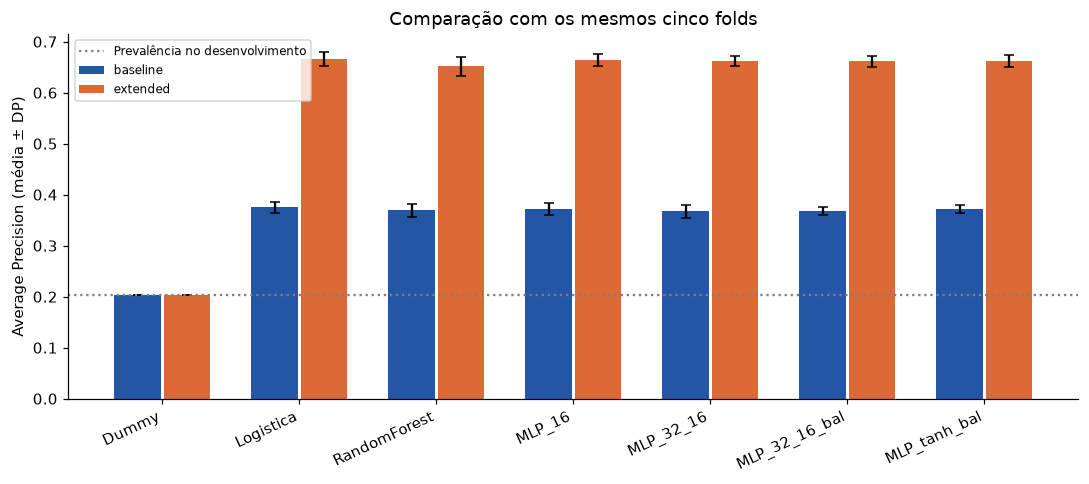

In [8]:
extended_mlp = cv_summary.query("feature_set == 'extended'")
extended_mlp = extended_mlp[extended_mlp['model'].isin(MLP_CONFIGS)]
chosen_mlp = extended_mlp.sort_values(
    ['AP_mean', 'AP_std', 'model'], ascending=[False, True, True]
).iloc[0]['model']
best_overall_row = cv_summary.sort_values(
    ['AP_mean', 'AP_std'], ascending=[False, True]
).iloc[0]
best_overall_key = (best_overall_row['feature_set'], best_overall_row['model'])
print('MLP escolhida pelo AP médio de CV em extended:', chosen_mlp)
print('Melhor combinação global na seleção por CV:', best_overall_key)
print('Configuração da MLP:', MLP_CONFIGS[chosen_mlp])

fig, ax = plt.subplots(figsize=(10, 4.5))
names = list(REFERENCES) + list(MLP_CONFIGS)
positions = np.arange(len(names))
for offset, feature_name, color in [(-0.18, 'baseline', '#2456A6'),
                                    (0.18, 'extended', '#DB6A36')]:
    table = cv_summary.query('feature_set == @feature_name').set_index('model').loc[names]
    ax.bar(positions + offset, table['AP_mean'], yerr=table['AP_std'],
           width=0.34, label=feature_name, color=color, capsize=3)
ax.axhline(y_dev.mean(), color='gray', linestyle=':', label='Prevalência no desenvolvimento')
ax.set(xticks=positions, xticklabels=names, ylabel='Average Precision (média ± DP)',
       title='Comparação com os mesmos cinco folds')
plt.setp(ax.get_xticklabels(), rotation=25, ha='right')
ax.legend(fontsize=8, loc='upper left')
fig.tight_layout(); plt.show()

## 6. Curvas de aprendizagem e diagnóstico de ajuste

As curvas abaixo mostram o **fold 1, definido previamente**, na divisão interna de early stopping. A linha vertical marca a época selecionada. As perdas exibidas são entropias cruzadas sem pesos, para comparar treino e validação na mesma escala; não incluem a penalização L2 do otimizador. Não são curvas do conjunto de teste.

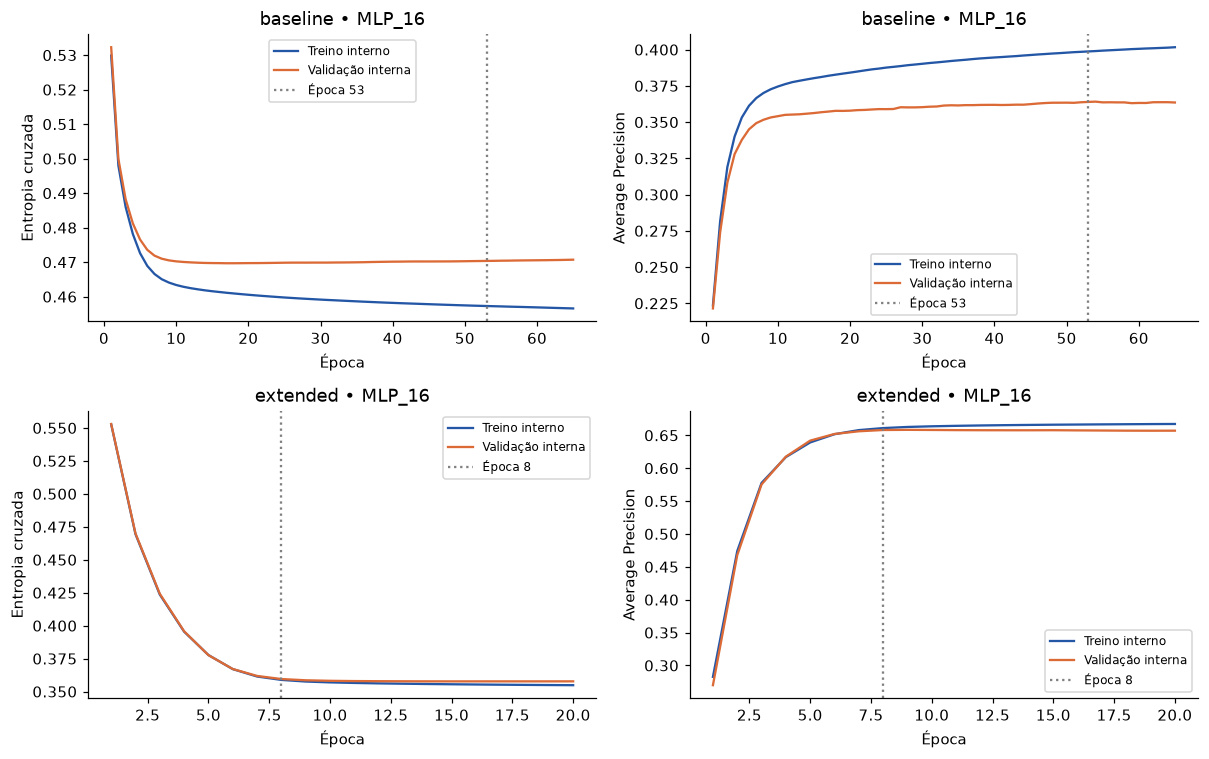

,Conjunto,Épocas por fold,Épocas para ajuste final
0,baseline,"[53, 13, 11, 25, 19]",19
1,extended,"[8, 15, 14, 19, 9]",14


In [9]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for row, feature_name in enumerate(FEATURE_SETS):
    h = learning_histories[(feature_name, chosen_mlp, 1)]
    best_epoch = epoch_choices[(feature_name, chosen_mlp)][0]
    for col, suffix, ylabel in [(0, 'loss', 'Entropia cruzada'), (1, 'ap', 'Average Precision')]:
        ax = axes[row, col]
        ax.plot(h['epoch'], h[f'train_{suffix}'], label='Treino interno')
        ax.plot(h['epoch'], h[f'val_{suffix}'], label='Validação interna')
        ax.axvline(best_epoch, color='gray', linestyle=':', label=f'Época {best_epoch}')
        ax.set(title=f'{feature_name} • {chosen_mlp}', xlabel='Época', ylabel=ylabel)
        ax.legend(fontsize=8)
fig.tight_layout(); plt.show()
display(pd.DataFrame([
    {'Conjunto': name, 'Épocas por fold': epoch_choices[(name, chosen_mlp)],
     'Épocas para ajuste final': int(np.median(epoch_choices[(name, chosen_mlp)]))}
    for name in FEATURE_SETS
]))

## 7. Análises adicionais no desenvolvimento

Usamos a mesma configuração MLP selecionada, sem nova busca de arquitetura, para verificar três pontos levantados no EDA:

- **autor_3:** apenas `performance_rating`, `tenure_years` e `on_pip`, conforme a sugestão de modelagem do autor.
- **sem_derivadas:** extended sem `is_recent_hire` e `high_salary`; investiga a contribuição das duas variáveis determinísticas.
- **conservador:** baseline sem `on_pip`, supondo que nem PIP nem decisões organizacionais estejam disponíveis antes do evento.

São análises exploratórias de CV, não resultados de teste nem uma demonstração de causalidade. O conjunto conservador ainda depende da disponibilidade temporal dos atributos restantes. Elas não alteram a escolha do modelo principal.

In [10]:
SENSITIVITY_SETS = {
    'autor_3': ['performance_rating', 'tenure_years', 'on_pip'],
    'sem_derivadas': [c for c in FEATURE_SETS['extended']
                      if c not in ['is_recent_hire', 'high_salary']],
    'conservador': [c for c in FEATURE_SETS['baseline'] if c != 'on_pip'],
}
for feature_name, columns in SENSITIVITY_SETS.items():
    run_cv(feature_name, columns, [chosen_mlp])

all_cv_results = pd.DataFrame(fold_results)
sensitivity = all_cv_results.query('model == @chosen_mlp').groupby('feature_set').agg(
    AP_mean=('AP', 'mean'), AP_std=('AP', 'std'),
    ROC_AUC_mean=('ROC_AUC', 'mean'), ROC_AUC_std=('ROC_AUC', 'std'),
).sort_values('AP_mean', ascending=False)
display(sensitivity.round(4))

autor_3            | MLP_16             | AP OOF=0.2676 | 9.1s
sem_derivadas      | MLP_16             | AP OOF=0.6586 | 17.8s
conservador        | MLP_16             | AP OOF=0.3594 | 14.3s


,AP_mean,AP_std,ROC_AUC_mean,ROC_AUC_std
feature_set,,,,
extended,0.6643,0.0120,0.8354,0.0115
sem_derivadas,0.6592,0.0123,0.8319,0.0117
baseline,0.3723,0.0115,0.6971,0.0071
conservador,0.3609,0.0154,0.6929,0.0078
autor_3,0.2716,0.0169,0.5756,0.0121


## 8. Limiar de decisão e congelamento das escolhas

O limiar padrão 0,5 não é necessariamente adequado para uma classe minoritária. Escolhemos o limiar que maximiza F1 nas previsões OOF de cada combinação a ser avaliada no teste. Em empates numéricos, escolhemos o maior limiar. A escolha por F1 é uma convenção acadêmica; não define custos reais de falso positivo e falso negativo.

O F1 OOF no limiar otimizado é um resultado de **ajuste**, otimista para avaliação. Não há uso dos rótulos de teste para escolher limiares. Dummy preserva 0,5 como referência de classe majoritária.

,Conjunto,Modelo,Limiar OOF,"F1 OOF @0,5",F1 OOF ajustado,Épocas finais
0,baseline,Dummy,0.5000,0.0000,0.0000,NaN
1,baseline,Logistica,0.2213,0.1177,0.4373,NaN
2,baseline,RandomForest,0.5225,0.4287,0.4327,NaN
3,baseline,MLP_16,0.2048,0.1122,0.4351,19.0
4,extended,Dummy,0.5000,0.0000,0.0000,NaN
5,extended,Logistica,0.3133,0.6060,0.6278,NaN
6,extended,RandomForest,0.6014,0.5995,0.6216,NaN
7,extended,MLP_16,0.2935,0.5998,0.6275,14.0


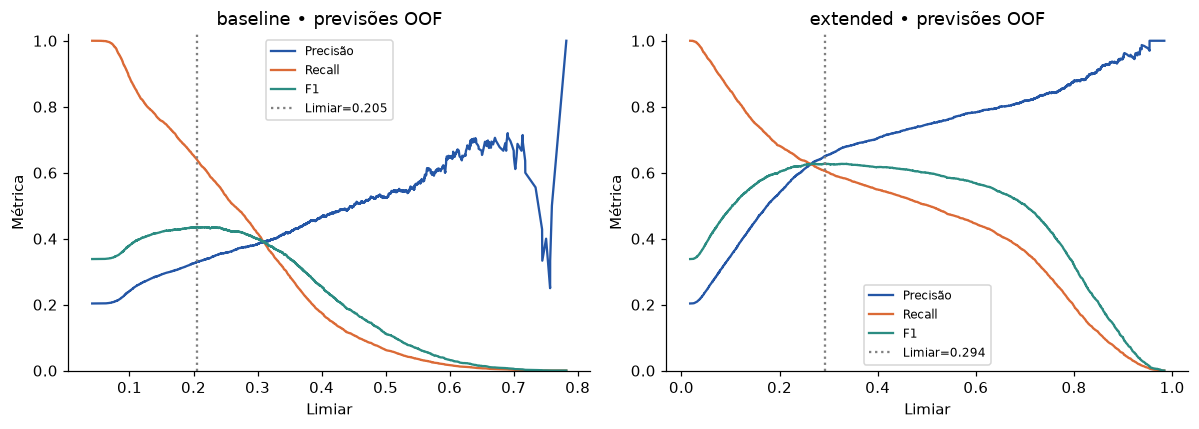

In [11]:
def choose_threshold(labels, probabilities):
    precision, recall, thresholds = precision_recall_curve(labels, probabilities)
    scores = 2 * precision[:-1] * recall[:-1] / np.maximum(
        precision[:-1] + recall[:-1], np.finfo(float).eps)
    candidates = np.flatnonzero(np.isclose(scores, scores.max(), atol=1e-12, rtol=0))
    return float(thresholds[candidates[-1]])

# Esta lista é definida e congelada ANTES da avaliação no teste.
FINAL_KEYS = [(features, model) for features in FEATURE_SETS
              for model in list(REFERENCES) + [chosen_mlp]]
if best_overall_key not in FINAL_KEYS:
    FINAL_KEYS.append(best_overall_key)
thresholds = {}
locked_epochs = {}
threshold_rows = []
for key in FINAL_KEYS:
    features, model_name = key
    prob = oof_predictions[key]
    threshold = 0.5 if model_name == 'Dummy' else choose_threshold(y_dev, prob)
    thresholds[key] = threshold
    locked_epochs[key] = (int(np.median(epoch_choices[key]))
                          if model_name in MLP_CONFIGS else None)
    threshold_rows.append({
        'Conjunto': features, 'Modelo': model_name, 'Limiar OOF': threshold,
        'F1 OOF @0,5': f1_score(y_dev, prob >= 0.5, zero_division=0),
        'F1 OOF ajustado': f1_score(y_dev, prob >= threshold, zero_division=0),
        'Épocas finais': locked_epochs[key],
    })
display(pd.DataFrame(threshold_rows).round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, feature_name in zip(axes, FEATURE_SETS):
    key = (feature_name, chosen_mlp)
    precision, recall, ts = precision_recall_curve(y_dev, oof_predictions[key])
    f1 = 2 * precision[:-1] * recall[:-1] / np.maximum(precision[:-1] + recall[:-1], 1e-12)
    ax.plot(ts, precision[:-1], label='Precisão')
    ax.plot(ts, recall[:-1], label='Recall')
    ax.plot(ts, f1, label='F1')
    ax.axvline(thresholds[key], color='gray', linestyle=':',
               label=f'Limiar={thresholds[key]:.3f}')
    ax.set(title=f'{feature_name} • previsões OOF', xlabel='Limiar', ylabel='Métrica', ylim=(0, 1.02))
    ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

## 9. Ajuste final e avaliação do teste reservado

Cada pré-processador é ajustado em todos os 24.000 registros de desenvolvimento. A MLP é reiniciada e treinada pelo número mediano de épocas selecionado nos folds, sem early stopping no teste. Os resultados abaixo usam os modelos, épocas e limiares já congelados.

As métricas de classificação da tabela utilizam o limiar OOF; AP, ROC-AUC, log loss e Brier utilizam os escores contínuos. AP/ROC-AUC maiores são melhores; log loss/Brier menores são melhores. O modelo principal continua sendo a MLP escolhida por CV, independentemente de diferenças observadas nesta tabela.

In [12]:
final_models, test_probabilities, test_rows = {}, {}, []
for key in FINAL_KEYS:
    feature_name, model_name = key
    columns = FEATURE_SETS[feature_name]
    if model_name in MLP_CONFIGS:
        model = fit_fixed_epochs(X_dev, y_dev, columns, MLP_CONFIGS[model_name],
                                 locked_epochs[key], SEED)
    else:
        model = Pipeline([
            ('preprocessing', make_preprocessor(columns)),
            ('model', clone(REFERENCES[model_name])),
        ]).fit(X_dev, y_dev)
    prob = model.predict_proba(X_test)[:, 1]
    final_models[key], test_probabilities[key] = model, prob
    test_rows.append({
        'feature_set': feature_name, 'model': model_name, 'threshold': thresholds[key],
        **classification_metrics(y_test, prob, thresholds[key]),
        'F1_at_05': f1_score(y_test, prob >= 0.5, zero_division=0),
    })
test_results = pd.DataFrame(test_rows).set_index(['feature_set', 'model'])
display(test_results.round(4))

for feature_name in FEATURE_SETS:
    key = (feature_name, chosen_mlp)
    pred = (test_probabilities[key] >= thresholds[key]).astype(int)
    print(f'\n{feature_name.upper()} • {chosen_mlp} • limiar {thresholds[key]:.4f}')
    print(classification_report(y_test, pred, target_names=['0 — mantido', '1 — demitido'],
                                digits=4, zero_division=0))

threshold      AP  ROC_AUC  Accuracy  \
feature_set model                                                
baseline    Dummy            0.5000  0.2035   0.5000    0.7965   
            Logistica        0.2213  0.3742   0.6982    0.6797   
            RandomForest     0.5225  0.3603   0.6909    0.6950   
            MLP_16           0.2048  0.3706   0.6950    0.6530   
extended    Dummy            0.5000  0.2035   0.5000    0.7965   
            Logistica        0.3133  0.6676   0.8330    0.8515   
            RandomForest     0.6014  0.6396   0.8285    0.8517   
            MLP_16           0.2935  0.6623   0.8319    0.8482   

                          Balanced_accuracy  Precision  Recall      F1  \
feature_set model                                                        
baseline    Dummy                    0.5000     0.0000  0.0000  0.0000   
            Logistica                0.6471     0.3367  0.5921  0.4293   
            RandomForest             0.6485     0.3478  0.5700  0.4320   
            MLP_16                   0.6474     0.3220  0.6380  0.4280   
extended    Dummy                    0.5000     0.0000  0.0000  0.0000   
            Logistica                0.7574     0.6458  0.5987  0.6213   
            RandomForest             0.7557     0.6479  0.5938  0.6197   
            MLP_16                   0.7605     0.6307  0.6126  0.6215   

                          Log_loss   Brier  F1_at_05  
feature_set model                                     
baseline    Dummy           0.5052  0.1621    0.0000  
            Logistica       0.4641  0.1481    0.1128  
            RandomForest    0.6278  0.2182    0.4306  
            MLP_16          0.4655  0.1485    0.1170  
extended    Dummy           0.5052  0.1621    0.0000  
            Logistica       0.3563  0.1064    0.6050  
            RandomForest    0.4853  0.1533    0.6018  
            MLP_16          0.3581  0.1071    0.6084


BASELINE • MLP_16 • limiar 0.2048
              precision    recall  f1-score   support

 0 — mantido     0.8766    0.6568    0.7510      4779
1 — demitido     0.3220    0.6380    0.4280      1221

    accuracy                         0.6530      6000
   macro avg     0.5993    0.6474    0.5895      6000
weighted avg     0.7637    0.6530    0.6852      6000


EXTENDED • MLP_16 • limiar 0.2935
              precision    recall  f1-score   support

 0 — mantido     0.9017    0.9083    0.9050      4779
1 — demitido     0.6307    0.6126    0.6215      1221

    accuracy                         0.8482      6000
   macro avg     0.7662    0.7605    0.7633      6000
weighted avg     0.8466    0.8482    0.8473      6000



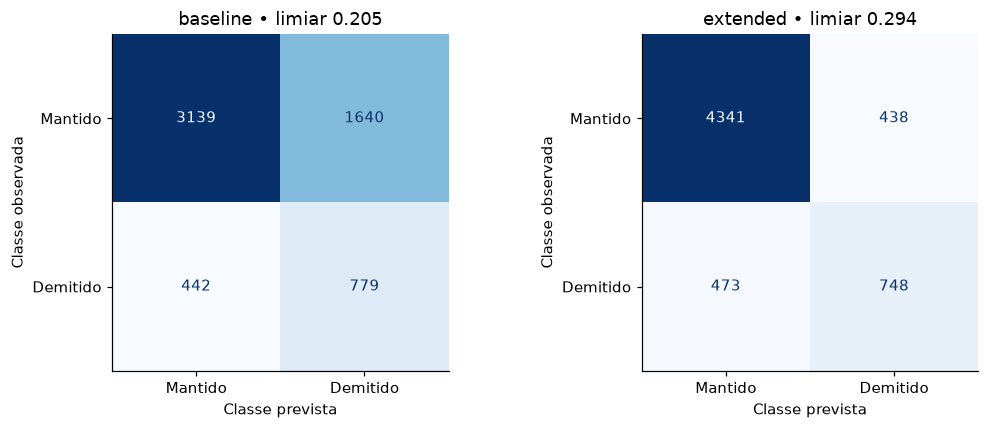

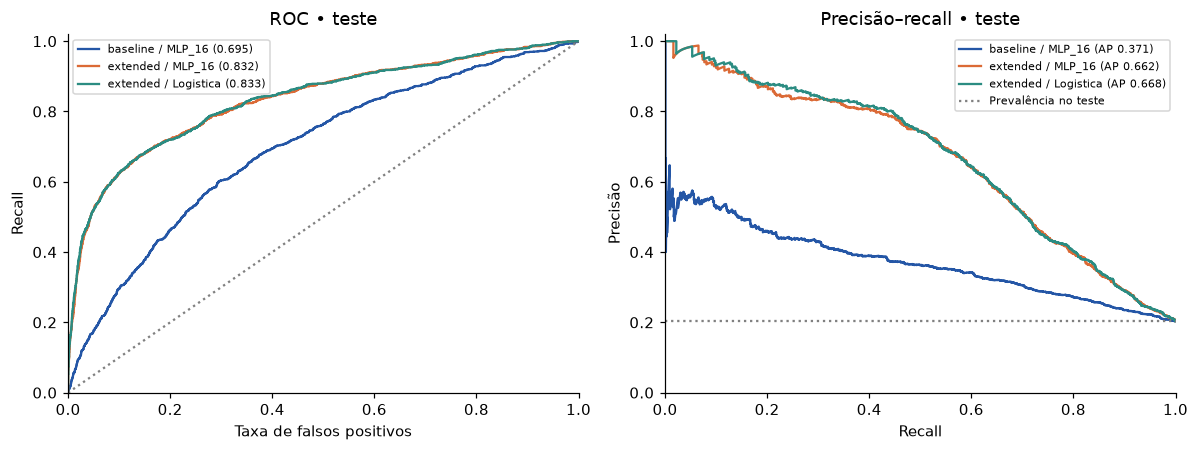

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, feature_name in zip(axes, FEATURE_SETS):
    key = (feature_name, chosen_mlp)
    pred = (test_probabilities[key] >= thresholds[key]).astype(int)
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, labels=[0, 1], display_labels=['Mantido', 'Demitido'],
        cmap='Blues', colorbar=False, ax=ax,
    )
    ax.set(title=f'{feature_name} • limiar {thresholds[key]:.3f}',
           xlabel='Classe prevista', ylabel='Classe observada')
fig.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for key in [(name, chosen_mlp) for name in FEATURE_SETS] + [('extended', 'Logistica')]:
    prob = test_probabilities[key]
    label = f'{key[0]} / {key[1]}'
    fpr, tpr, _ = roc_curve(y_test, prob)
    precision, recall, _ = precision_recall_curve(y_test, prob)
    axes[0].plot(fpr, tpr, label=f'{label} ({roc_auc_score(y_test, prob):.3f})')
    axes[1].plot(recall, precision, label=f'{label} (AP {average_precision_score(y_test, prob):.3f})')
axes[0].plot([0, 1], [0, 1], color='gray', linestyle=':')
axes[0].set(title='ROC • teste', xlabel='Taxa de falsos positivos', ylabel='Recall')
axes[1].axhline(y_test.mean(), color='gray', linestyle=':', label='Prevalência no teste')
axes[1].set(title='Precisão–recall • teste', xlabel='Recall', ylabel='Precisão')
for ax in axes:
    ax.set(xlim=(0, 1), ylim=(0, 1.02)); ax.legend(fontsize=7, loc='best')
fig.tight_layout(); plt.show()

## 10. Incerteza e comparação pareada

Bootstrap estratificado de 1.000 reamostragens dos registros de teste, com os modelos e limiares fixos. O mesmo sorteio é usado para baseline e extended; portanto, o intervalo do ganho é **pareado**. Os intervalos percentis de 95% são condicionais a estes dados e treinos: não incluem a variabilidade de repetir toda a seleção ou mudar a população. A prevalência de teste é mantida nas reamostragens.

In [14]:
rng = np.random.default_rng(SEED)
yt = y_test.to_numpy()
negative_indices, positive_indices = np.flatnonzero(yt == 0), np.flatnonzero(yt == 1)
bootstrap_rows = []
for _ in range(BOOTSTRAPS):
    ix = np.concatenate([
        rng.choice(negative_indices, len(negative_indices), replace=True),
        rng.choice(positive_indices, len(positive_indices), replace=True),
    ])
    row = {}
    for feature_name in FEATURE_SETS:
        key = (feature_name, chosen_mlp)
        prob = test_probabilities[key][ix]
        row[f'{feature_name}_AP'] = average_precision_score(yt[ix], prob)
        row[f'{feature_name}_ROC_AUC'] = roc_auc_score(yt[ix], prob)
        row[f'{feature_name}_F1'] = f1_score(yt[ix], prob >= thresholds[key])
    row['delta_AP'] = row['extended_AP'] - row['baseline_AP']
    row['delta_ROC_AUC'] = row['extended_ROC_AUC'] - row['baseline_ROC_AUC']
    bootstrap_rows.append(row)
bootstrap = pd.DataFrame(bootstrap_rows)
interval_rows = []
for feature_name in FEATURE_SETS:
    for metric in ['AP', 'ROC_AUC', 'F1']:
        lo, hi = np.quantile(bootstrap[f'{feature_name}_{metric}'], [0.025, 0.975])
        interval_rows.append({'Comparação': feature_name, 'Métrica': metric,
            'Estimativa': test_results.loc[(feature_name, chosen_mlp), metric],
            'IC95 inferior': lo, 'IC95 superior': hi})
for metric in ['AP', 'ROC_AUC']:
    lo, hi = np.quantile(bootstrap[f'delta_{metric}'], [0.025, 0.975])
    delta = (test_results.loc[('extended', chosen_mlp), metric]
             - test_results.loc[('baseline', chosen_mlp), metric])
    interval_rows.append({'Comparação': 'extended − baseline', 'Métrica': metric,
                         'Estimativa': delta, 'IC95 inferior': lo, 'IC95 superior': hi})
confidence_intervals = pd.DataFrame(interval_rows)
display(confidence_intervals.round(4))

,Comparação,Métrica,Estimativa,IC95 inferior,IC95 superior
0,baseline,AP,0.3706,0.3470,0.3963
1,baseline,ROC_AUC,0.6950,0.6774,0.7107
2,baseline,F1,0.4280,0.4114,0.4441
3,extended,AP,0.6623,0.6369,0.6861
4,extended,ROC_AUC,0.8319,0.8177,0.8454
5,extended,F1,0.6215,0.6016,0.6414
6,extended − baseline,AP,0.2916,0.2644,0.3177
7,extended − baseline,ROC_AUC,0.1370,0.1223,0.1521


## 11. Importância por permutação e erros

Permutamos cada **coluna original**, antes do one-hot, e medimos a queda de AP da MLP extended no teste (10 repetições). Esta análise ocorre depois da avaliação final e não é utilizada para selecionar atributos ou reajustar o modelo. O desvio padrão representa as repetições da permutação, não um intervalo de confiança populacional.

A importância mede dependência preditiva do modelo, não efeito causal. Variáveis correlacionadas ou derivadas podem compartilhar importância; permutações independentes também podem criar combinações improváveis. As taxas de erro por departamento são descritivas, com seus denominadores explícitos.

,Atributo,Queda_AP,DP
10,team_wind_down,0.3723,0.0052
12,role_redundant,0.0290,0.0017
11,cost_center_type,0.0268,0.0048
7,on_pip,0.0199,0.0024
1,performance_rating,0.0158,0.0021
6,is_recent_hire,0.0132,0.0028
8,high_salary,0.0116,0.0023
4,mgmt_layer,0.0102,0.0014
0,tenure_years,0.0009,0.0016
5,level,0.0004,0.0007


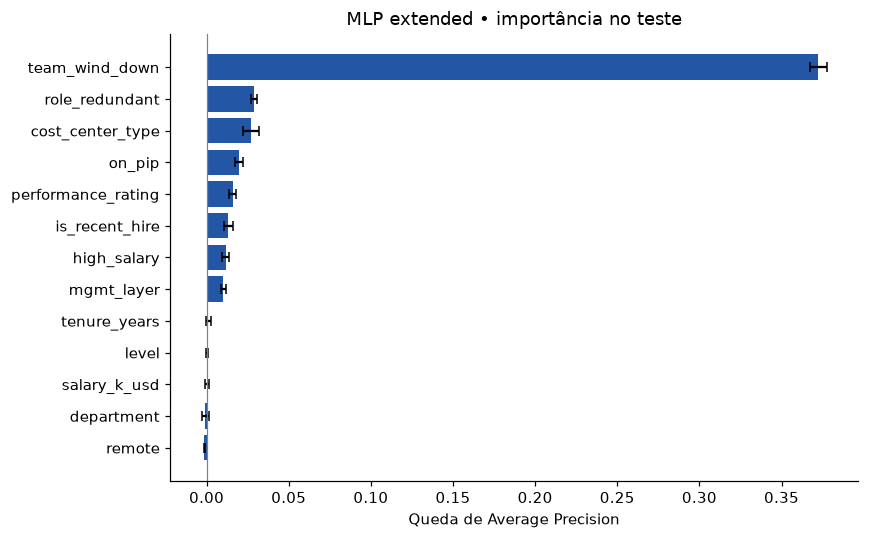

,Departamento,N,Positivos,Negativos,FP,FN,Recall,FPR
1,engineering,1468,183,1285,68,102,0.4426,0.0529
7,sales,1009,131,878,39,69,0.4733,0.0444
8,support,723,174,549,66,64,0.6322,0.1202
4,product,598,73,525,34,38,0.4795,0.0648
3,marketing,571,146,425,37,52,0.6438,0.0871
6,research,490,171,319,76,42,0.7544,0.2382
2,g_and_a,456,170,286,53,42,0.7529,0.1853
0,data,353,50,303,14,33,0.3400,0.0462
5,recruiting,332,123,209,51,31,0.7480,0.2440


In [15]:
main_key = ('extended', chosen_mlp)
importance = permutation_importance(
    final_models[main_key], X_test[FEATURE_SETS['extended']], y_test,
    scoring='average_precision', n_repeats=10, random_state=SEED, n_jobs=1,
)
importance_table = pd.DataFrame({
    'Atributo': FEATURE_SETS['extended'],
    'Queda_AP': importance.importances_mean, 'DP': importance.importances_std,
}).sort_values('Queda_AP', ascending=False)
display(importance_table.round(4))
plot_table = importance_table.sort_values('Queda_AP')
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(plot_table['Atributo'], plot_table['Queda_AP'], xerr=plot_table['DP'],
        color='#2456A6', capsize=3)
ax.axvline(0, color='gray', linewidth=0.8)
ax.set(title='MLP extended • importância no teste', xlabel='Queda de Average Precision')
fig.tight_layout(); plt.show()

error_data = X_test[['department']].copy()
error_data['real'] = y_test
error_data['previsto'] = (test_probabilities[main_key] >= thresholds[main_key]).astype(int)
department_rows = []
for department, group in error_data.groupby('department'):
    tn, fp, fn, tp = confusion_matrix(group['real'], group['previsto'], labels=[0, 1]).ravel()
    department_rows.append({
        'Departamento': department, 'N': len(group), 'Positivos': int(tp + fn),
        'Negativos': int(tn + fp), 'FP': int(fp), 'FN': int(fn),
        'Recall': tp / (tp + fn) if tp + fn else np.nan,
        'FPR': fp / (fp + tn) if fp + tn else np.nan,
    })
department_errors = pd.DataFrame(department_rows).sort_values('N', ascending=False)
display(department_errors.round(4))

## 12. Conclusões calculadas a partir da execução

In [17]:
base = test_results.loc[('baseline', chosen_mlp)]
ext = test_results.loc[('extended', chosen_mlp)]
logistic = test_results.loc[('extended', 'Logistica')]
delta_ci = confidence_intervals.query("Comparação == 'extended − baseline' and Métrica == 'AP'").iloc[0]
top_feature = importance_table.iloc[0]
author_auc = sensitivity.loc['autor_3', 'ROC_AUC_mean']
redundancy_delta = sensitivity.loc['sem_derivadas', 'AP_mean'] - sensitivity.loc['extended', 'AP_mean']
tn, fp, fn, tp = confusion_matrix(
    y_test, test_probabilities[main_key] >= thresholds[main_key], labels=[0, 1]).ravel()
direction = 'maior' if ext['AP'] >= logistic['AP'] else 'menor'
display(Markdown(f"""
**Rede selecionada:** `{chosen_mlp}`, escolhida apenas no desenvolvimento.

- **Contribuição dos fatores organizacionais:** o AP passou de **{base['AP']:.4f}** (baseline) para **{ext['AP']:.4f}** (extended). O ganho foi **{ext['AP']-base['AP']:.4f}**, com IC95% bootstrap pareado **[{delta_ci['IC95 inferior']:.4f}; {delta_ci['IC95 superior']:.4f}]**. A ROC-AUC passou de **{base['ROC_AUC']:.4f}** para **{ext['ROC_AUC']:.4f}**.
- **Desempenho da MLP extended:** F1 **{ext['F1']:.4f}**, precisão **{ext['Precision']:.4f}**, recall **{ext['Recall']:.4f}**, usando limiar **{ext['threshold']:.4f}** definido por OOF. No teste, foram **{tp} verdadeiros positivos, {fn} falsos negativos, {fp} falsos positivos e {tn} verdadeiros negativos**.
- **Referência linear:** regressão logística extended obteve AP **{logistic['AP']:.4f}**. O AP da MLP foi {direction} nesta amostra; a diferença pontual não comprova superioridade estatística. A comparação é relevante porque o alvo foi gerado por uma função logística.
- **Importância:** `{top_feature['Atributo']}` produziu a maior queda média de AP por permutação (**{top_feature['Queda_AP']:.4f}**). Isso descreve o uso dos atributos pelo modelo, não uma causa de demissão real.
- **Baseline original do autor:** com apenas três atributos, a ROC-AUC média de CV foi **{author_auc:.4f}**. Esse experimento é distinto do baseline de dez atributos do projeto.
- **Redundância:** remover `is_recent_hire` e `high_salary` mudou o AP médio de CV em **{redundancy_delta:+.4f}**. Essa comparação é exploratória e não motivou um novo ajuste após olhar o teste.
"""))

# Diagnóstico objetivo de generalização nas curvas, sem conclusões causais.
for feature_name in FEATURE_SETS:
    h = learning_histories[(feature_name, chosen_mlp, 1)]
    best_epoch = epoch_choices[(feature_name, chosen_mlp)][0]
    chosen_point = h.set_index('epoch').loc[best_epoch]
    print(f'{feature_name} — AP treino interno: {chosen_point.train_ap:.4f}; '
          f'AP validação interna: {chosen_point.val_ap:.4f}; época: {best_epoch}.')


**Rede selecionada:** `MLP_16`, escolhida apenas no desenvolvimento.

- **Contribuição dos fatores organizacionais:** o AP passou de **0.3706** (baseline) para **0.6623** (extended). O ganho foi **0.2916**, com IC95% bootstrap pareado **[0.2644; 0.3177]**. A ROC-AUC passou de **0.6950** para **0.8319**.
- **Desempenho da MLP extended:** F1 **0.6215**, precisão **0.6307**, recall **0.6126**, usando limiar **0.2935** definido por OOF. No teste, foram **748 verdadeiros positivos, 473 falsos negativos, 438 falsos positivos e 4341 verdadeiros negativos**.
- **Referência linear:** regressão logística extended obteve AP **0.6676**. O AP da MLP foi menor nesta amostra; a diferença pontual não comprova superioridade estatística. A comparação é relevante porque o alvo foi gerado por uma função logística.
- **Importância:** `team_wind_down` produziu a maior queda média de AP por permutação (**0.3723**). Isso descreve o uso dos atributos pelo modelo, não uma causa de demissão real.
- **Baseline original do autor:** com apenas três atributos, a ROC-AUC média de CV foi **0.5756**. Esse experimento é distinto do baseline de dez atributos do projeto.
- **Redundância:** remover `is_recent_hire` e `high_salary` mudou o AP médio de CV em **-0.0051**. Essa comparação é exploratória e não motivou um novo ajuste após olhar o teste.


baseline — AP treino interno: 0.3988; AP validação interna: 0.3639; época: 53.
extended — AP treino interno: 0.6610; AP validação interna: 0.6581; época: 8.


### Limitações e próximos passos

- O gerador favorece fatores estruturais por construção. Bom desempenho recupera esse mecanismo; não comprova as afirmações sociais da descrição do dataset.
- `team_wind_down`, `role_redundant`, `cost_center_type` e `on_pip` só podem ser entradas se já existirem no momento da previsão. O experimento extended pressupõe essa disponibilidade; não a comprova.
- O EDA observou a base completa. Para uma validação mais forte, usar outra amostra sintética independente ou dados externos apropriados, com recorte temporal definido.
- Perfis coincidentes, categorias relacionadas a departamento e atributos derivados limitam interpretações isoladas. O split não mede transferência entre empresas, equipes ou períodos.
- F1 atribui uma convenção de compromisso entre precisão e recall. Não foram fornecidos custos de erro ou uma política operacional. Os escores, sobretudo com pesos de classe, exigiriam análise e calibração separadas antes de qualquer interpretação probabilística.
- A busca cobre quatro configurações e uma família de sementes. Resultados próximos devem ser tratados como próximos; replicar treinos com outras sementes é um próximo experimento, não uma garantia já demonstrada.

## 13. Reutilização do experimento

O modelo final inclui o pré-processamento. A função abaixo recebe registros com as mesmas colunas e retorna o escore e a classe no limiar congelado. O exemplo utiliza somente registros sintéticos do teste. A exportação é opcional e desativada por padrão para manter a entrega em um único notebook.

In [18]:
def predict_synthetic_records(records, feature_set='extended'):
    key = (feature_set, chosen_mlp)
    missing_columns = set(FEATURE_SETS[feature_set]) - set(records.columns)
    if missing_columns:
        raise ValueError(f'Colunas ausentes: {sorted(missing_columns)}')
    scores = final_models[key].predict_proba(records)[:, 1]
    return pd.DataFrame({
        'escore_classe_1': scores,
        'classe_prevista': (scores >= thresholds[key]).astype(int),
        'limiar': thresholds[key],
    }, index=records.index)

display(predict_synthetic_records(X_test.head()).join(y_test.rename('classe_real')))

EXPORTAR_ARQUIVOS = False
if EXPORTAR_ARQUIVOS:
    import joblib
    output = Path('resultados_classificacao')
    output.mkdir(exist_ok=True)
    for feature_name in FEATURE_SETS:
        key = (feature_name, chosen_mlp)
        joblib.dump({
            'pipeline': final_models[key], 'threshold': thresholds[key],
            'features': FEATURE_SETS[feature_name], 'model_name': chosen_mlp,
            'epochs': locked_epochs[key], 'versions': VERSIONS,
            'dataset_sha256': DATASET_SHA256,
        }, output / f'mlp_{feature_name}.joblib')
    cv_summary.to_csv(output / 'validacao_cruzada.csv', index=False)
    test_results.to_csv(output / 'metricas_teste.csv')
    confidence_intervals.to_csv(output / 'intervalos_confianca.csv', index=False)
    importance_table.to_csv(output / 'importancia_permutacao.csv', index=False)
    print('Arquivos exportados em:', output.resolve())
else:
    print('Exportação desativada. Modelos e tabelas estão disponíveis nesta sessão.')

,escore_classe_1,classe_prevista,limiar,classe_real
24169,0.159712,0,0.293501,0
9125,0.052744,0,0.293501,0
23111,0.062296,0,0.293501,0
26156,0.047882,0,0.293501,1
185,0.117200,0,0.293501,0


Exportação desativada. Modelos e tabelas estão disponíveis nesta sessão.


## Referências e reprodutibilidade

1. Sergey Nefedov. [Layoff Survival — Who Actually Gets Cut?](https://www.kaggle.com/datasets/sergionefedov/layoff-survival-who-actually-gets-cut). Versão 1, CC0. [Endpoint da versão utilizada](https://www.kaggle.com/api/v1/datasets/download/sergionefedov/layoff-survival-who-actually-gets-cut?datasetVersionNumber=1).
2. Scikit-learn. [MLPClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html), [Average Precision](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html) e [OneHotEncoder](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html).

Fontes consultadas em 12/11/2026. Dados, sementes, configurações, métricas e versões executadas estão registrados neste notebook. Variações de biblioteca, BLAS e plataforma podem causar pequenas diferenças numéricas. Todos os resultados exibidos foram calculados pelo código; nenhum valor de desempenho foi preenchido manualmente.